# Controlled two-task paradigm: A → B → A

**Question.** When a one-module network learns task B after task A, how does A's
geometry change? How much of the change is set by the task relation (Hamming(A, B),
input change s_f) and how much by the learner (richness γ₀)? What does relearning A
recover?

**Slot.** `docs/26` Part B, two-task paradigm: the controlled experiment that comes
before the stream (Kati, 2026-11-06). It is part of the `docs/24` §4 core.

**Pre-commit.** None yet. This notebook establishes the instrument (sections 1–4) and
reports **observations at n = 3, not claims**. Readings are not named, so nothing here
is read as a finding.

**Self-contained.** Everything lives in `aba_lib.py` next to this notebook: the
generator, the 1M network, training, NTK, and a vendored copy of GLUE. Section 3
asserts that the GLUE copy matches `src.glue.core`.

## 1. Config

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[_v] = "1"          # before numpy is imported anywhere in this kernel

QUICK = True        # QUICK: M=50, n_t=50, n=3.  Full: M=150, n_t=200, n=8.
RUN_GRID = False    # the grid runs only when set; the timing arm and the identity control always run
WORKERS = None      # None → cpu_count − 1 spawned workers

import sys, time, json, math
from pathlib import Path
here = Path.cwd().resolve()
REPO = next(p for p in [here, *here.parents] if (p / ".git").exists())
sys.path[:0] = [str(REPO / "notebooks" / "core"), str(REPO)]

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import aba_lib as L

cfg = L.ABAConfig.make(QUICK)
STAMP = L.git_stamp()

def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

md_table(["parameter", "value"], [[k, v] for k, v in vars(cfg).items()])
print(f"aba_lib hash {L.lib_hash()}   commit {STAMP['commit']}   dirty {STAMP['dirty']}")
print(f"numpy {np.__version__}   python {sys.version.split()[0]}   cache {L.cache_path(cfg).relative_to(REPO)}")

| parameter | value |
|---|---|
| quick | True |
| P | 16 |
| d | 150 |
| D | 4 |
| R | 1.0 |
| M | 50 |
| N | 300 |
| lr0 | 5.0 |
| n_base | 64 |
| target_loss | 0.05 |
| max_steps | 20000 |
| record_every | 25 |
| n_t | 50 |
| center_policy | all |
| ntk_per_manifold | 20 |
| probe_hamming | 4 |
| gammas | (0.1, 10.0) |
| hammings | (0, 4, 8) |
| s_fs | (1.0, 0.9, 0.1) |
| n_seeds | 3 |

aba_lib hash 688d1483b6c0a738   commit f4265a60954f   dirty True
numpy 2.4.6   python 3.11.9   cache results\aba\QUICK_688d1483b6c0a738.jsonl


In [2]:
# Palette: reference categorical order (blue, orange, aqua); diverging blue ↔ orange through a neutral grey.
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
GAMMA_COL = {cfg.gammas[0]: BLUE, cfg.gammas[1]: ORANGE}
LABEL_COL = {1: BLUE, -1: ORANGE}
from matplotlib.colors import LinearSegmentedColormap
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2.0, "font.size": 9})
CHECKS = []   # (check, PASS/FAIL, detail): validation checks, kept apart from observations
def check(name, ok, detail=""):
    CHECKS.append((name, "PASS" if ok else "**FAIL**", detail))
    print(("PASS " if ok else "FAIL ") + name + (f"  ({detail})" if detail else ""))

## 2. Manifolds

Seed 0 is shown. A and y_A are shared by every cell and both γ₀. B is A's
arrangement with centres redrawn at ρ = s_f (axes and shapes held), labelled by a
dichotomy at the stated Hamming distance from y_A. **At s_f = 1.0, B's points are
A's points exactly.**

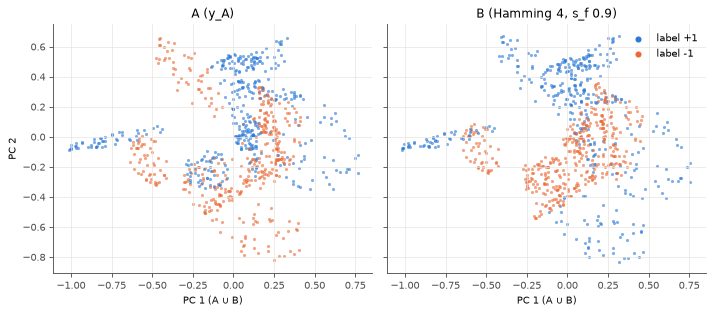

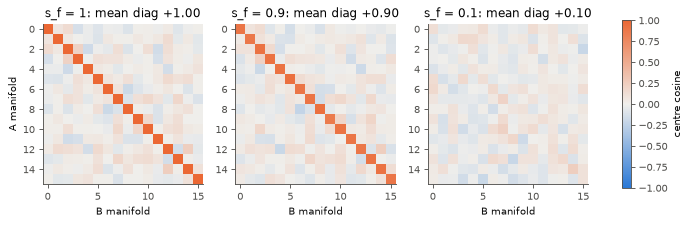

In [3]:
base = L.seed_base(cfg, 0)
H_SHOW, SF_SHOW = 4, 0.9
B_show = L.b_arrangement(cfg, base, SF_SHOW)
pts = np.concatenate([base.A.points.reshape(-1, cfg.d), B_show.points.reshape(-1, cfg.d)])
mu = pts.mean(0); _, _, Vt = np.linalg.svd(pts - mu, full_matrices=False); basis = Vt[:2]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, arr, y, title in [(axes[0], base.A, base.y_A, "A (y_A)"),
                          (axes[1], B_show, base.y_Bs[H_SHOW], f"B (Hamming {H_SHOW}, s_f {SF_SHOW})")]:
    for m in range(cfg.P):
        Z = (arr.points[m] - mu) @ basis.T
        ax.scatter(Z[:, 0], Z[:, 1], s=8, color=LABEL_COL[int(y[m])], alpha=0.6, linewidths=0)
    ax.set_title(title); ax.set_xlabel("PC 1 (A ∪ B)")
axes[0].set_ylabel("PC 2")
for lab, col in LABEL_COL.items():
    axes[1].scatter([], [], color=col, s=20, label=f"label {lab:+d}")
axes[1].legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.4))
for ax, sf in zip(axes, cfg.s_fs):
    C = L.centre_cosines(base.A.centers, L.b_arrangement(cfg, base, sf).centers)
    im = ax.imshow(C, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_title(f"s_f = {sf:g}: mean diag {np.mean(np.diag(C)):+.2f}"); ax.set_xlabel("B manifold"); ax.grid(False)
axes[0].set_ylabel("A manifold"); fig.colorbar(im, ax=axes, shrink=0.8, label="centre cosine"); plt.show()

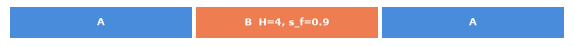

label relations, seed 0 (signed s_r = 1 − 2·Hamming/P):


| Hamming(A,B) | s_r(y_A, y_B) | s_r(y*, y_A) | s_r(y*, y_B) |
|---|---|---|---|
| 0 | +1.000 | +0.500 | +0.500 |
| 4 | +0.500 | +0.500 | +0.000 |
| 8 | +0.000 | +0.500 | +0.250 |

In [4]:
def stream_strip(ax, h, sf, widths=(1, 1, 1)):
    x = 0
    for (lab, col), w in zip([("A", BLUE), (f"B  H={h}, s_f={sf:g}", ORANGE), ("A", BLUE)], widths):
        ax.add_patch(plt.Rectangle((x + 0.01, 0), w - 0.02, 1, color=col, alpha=0.85, linewidth=0))
        ax.text(x + w / 2, 0.5, lab, ha="center", va="center", color="white", fontsize=9, weight="bold")
        x += w
    ax.set_xlim(0, x); ax.set_ylim(0, 1); ax.axis("off")

fig, ax = plt.subplots(figsize=(9, 0.5)); stream_strip(ax, H_SHOW, SF_SHOW); plt.show()
print("label relations, seed 0 (signed s_r = 1 − 2·Hamming/P):")
md_table(["Hamming(A,B)", "s_r(y_A, y_B)", "s_r(y*, y_A)", "s_r(y*, y_B)"],
         [[h, f"{L.s_r(base.y_A, yb):+.3f}", f"{L.s_r(base.y_star, base.y_A):+.3f}",
           f"{L.s_r(base.y_star, yb):+.3f}"] for h, yb in base.y_Bs.items()])

## 3. Estimator validation (must pass)

In [5]:
# (a) Vendored GLUE equals src.glue.core on one example, when src imports.
try:
    from src.glue.core import glue_measures as src_glue, Ensemble as SrcEnsemble
except Exception as e:  # noqa: BLE001
    src_glue = None; print("src not importable, comparison skipped:", e)
if src_glue is not None:
    mans = L.as_manifolds(base.A.points)
    y = base.y_A.astype(float)
    a = L.glue_measures(mans, np.random.default_rng(11), n_t=20, ensemble=L.Ensemble("retained", y)).to_dict()
    b = src_glue(mans, np.random.default_rng(11), n_t=20, ensemble=SrcEnsemble("retained", y)).to_dict()
    diff = max(abs(a[k] - b[k]) for k in a if isinstance(a[k], float))
    assert diff == 0.0, f"vendored GLUE differs from src.glue.core by {diff}"
    check("vendored GLUE == src.glue.core (retained y_A, input manifolds)", True, f"max |diff| = {diff:g}")

PASS vendored GLUE == src.glue.core (retained y_A, input manifolds)  (max |diff| = 0)


In [6]:
# (b) Identity residual and (c) capacity falls with R and with D, on input manifolds.
rows, alphas_R, alphas_D, resid = [], [], [], []
for R in (0.5, 1.0, 2.0):
    arr = L.make_arrangement(cfg.P, cfg.d, cfg.D, R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_R.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={R}, D={cfg.D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
for D in (2, 4, 8):
    arr = L.make_arrangement(cfg.P, cfg.d, D, cfg.R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_D.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={cfg.R}, D={D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
md_table(["input manifolds", "α (retained y_A)", "identity residual"], rows)
check("identity residual ≈ 0", max(resid) < 1e-10, f"max {max(resid):.1e}")
check("capacity falls as R grows (0.5 → 1 → 2)", bool(np.all(np.diff(alphas_R) < 0)), str([round(a, 4) for a in alphas_R]))
check("capacity falls as D grows (2 → 4 → 8)", bool(np.all(np.diff(alphas_D) < 0)), str([round(a, 4) for a in alphas_D]))

| input manifolds | α (retained y_A) | identity residual |
|---|---|---|
| R=0.5, D=4 | 0.7438 | 0.0e+00 |
| R=1.0, D=4 | 0.4552 | 1.2e-16 |
| R=2.0, D=4 | 0.3129 | 1.8e-16 |
| R=1.0, D=2 | 0.6495 | 1.7e-16 |
| R=1.0, D=4 | 0.4552 | 1.2e-16 |
| R=1.0, D=8 | 0.3402 | 1.6e-16 |

PASS identity residual ≈ 0  (max 1.8e-16)
PASS capacity falls as R grows (0.5 → 1 → 2)  ([0.7438, 0.4552, 0.3129])
PASS capacity falls as D grows (2 → 4 → 8)  ([0.6495, 0.4552, 0.3402])


In [7]:
# (d) Noise floor: SD of log α over K estimator seeds, on the init representation (identical across γ0).
K_FLOOR = 6
net0 = L.OneModuleNet(base.W0, 1.0, cfg)
P_, M_, d_ = base.A.points.shape
Hrep = net0.hidden(base.A.points.reshape(-1, d_)).reshape(P_, M_, -1)
logs = [math.log(L.capacity(L.as_manifolds(Hrep), base.y_A, cfg, [L.SALT, 0, 1000 + k])["alpha"]) for k in range(K_FLOOR)]
FLOOR = float(np.std(logs, ddof=1))
print(f"noise floor: SD(log α) over {K_FLOOR} estimator seeds = {FLOOR:.4f}  (n_t = {cfg.n_t})")
print("arms share one estimator seed across boundaries, so paired differences carry less than this.")

noise floor: SD(log α) over 6 estimator seeds = 0.0367  (n_t = 50)
arms share one estimator seed across boundaries, so paired differences carry less than this.


## 4. Network validation (must pass)

In [8]:
nets = {g: L.OneModuleNet(base.W0, g, cfg) for g in cfg.gammas}
XA, yA = L.flatten(base.A.points, base.y_A)
check("initial loss = 0.5 for every γ0", all(n.loss(XA, yA) == 0.5 for n in nets.values()),
      str({g: n.loss(XA, yA) for g, n in nets.items()}))
check("hidden init identical across γ0 (bitwise)", np.array_equal(nets[cfg.gammas[0]].W, nets[cfg.gammas[1]].W))
probe = np.concatenate([base.A.points[m, base.ntk_idx[m]] for m in range(cfg.P)])
_, KW0 = nets[cfg.gammas[0]].ntk_blocks(probe)
check("K_W(0) = 0 (readout starts at 0)", float(np.abs(KW0).max()) == 0.0)
tmp = L.OneModuleNet(base.W0, 1.0, cfg); tmp.u = np.random.default_rng(3).standard_normal(cfg.N)
fd = L.ntk_fd_check(tmp, probe[:3], np.random.default_rng(4))
check("analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference",
      fd["K_vs_JJt_rel"] < 1e-12 and fd["Jdelta_vs_fd_rel"] < 1e-5, str({k: f"{v:.1e}" for k, v in fd.items()}))

PASS initial loss = 0.5 for every γ0  ({0.1: 0.5, 10.0: 0.5})
PASS hidden init identical across γ0 (bitwise)
PASS K_W(0) = 0 (readout starts at 0)
PASS analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference  ({'K_vs_JJt_rel': '3.4e-16', 'Jdelta_vs_fd_rel': '5.9e-08'})


In [9]:
# Lazy/rich separation after A, and reaching the target within budget, for every seed and γ0.
sep_rows, sep, budget_ok = [], {}, []
for seed in range(cfg.n_seeds):
    b = L.seed_base(cfg, seed)
    X, y = L.flatten(b.A.points, b.y_A)
    pr = np.concatenate([b.A.points[m, b.ntk_idx[m]] for m in range(cfg.P)])
    yp = np.repeat(b.y_A.astype(float), b.ntk_idx.shape[1])
    for g in cfg.gammas:
        n = L.OneModuleNet(b.W0, g, cfg); Ku0, KW0 = n.ntk_blocks(pr)
        t = L.train_to_criterion(n, X, y, cfg)
        budget_ok.append((seed, g, t["status"], t["steps"]))
        sep[(seed, g)] = L.richness_snapshot(n, Ku0 + KW0, Ku0, pr, yp, pr, yp)
    lo, hi = sep[(seed, cfg.gammas[0])], sep[(seed, cfg.gammas[1])]
    sep_rows.append([seed] + [f"{lo[k]:.3g} → {hi[k]:.3g}  (×{hi[k] / lo[k]:.1f})" for k in ("weight_change", "dK_u", "dK_full")])
md_table(["seed", f"weight change γ0={cfg.gammas[0]:g} → {cfg.gammas[1]:g}", "ΔK_u", "ΔK full"], sep_rows)
for k in ("weight_change", "dK_u", "dK_full"):
    check(f"rich > lazy after A in {k}, every seed",
          all(sep[(s, cfg.gammas[1])][k] > sep[(s, cfg.gammas[0])][k] for s in range(cfg.n_seeds)),
          "direction only; any ratio threshold is Kati's")
md_table(["seed", "γ0", "status", "steps on A"], [[s, f"{g:g}", st, n] for s, g, st, n in budget_ok])
check(f"every γ0 reaches loss {cfg.target_loss} within {cfg.max_steps} steps at lr0 = {cfg.lr0}",
      all(st == "converged" for _, _, st, _ in budget_ok), "a failure is reported, never re-pinned")

| seed | weight change γ0=0.1 → 10 | ΔK_u | ΔK full |
|---|---|---|---|
| 0 | 0.0186 → 0.598  (×32.2) | 0.0449 → 8.06  (×179.3) | 0.182 → 33.4  (×183.3) |
| 1 | 0.0194 → 0.601  (×30.9) | 0.0481 → 8.28  (×172.0) | 0.184 → 32.2  (×174.7) |
| 2 | 0.0218 → 0.645  (×29.5) | 0.0429 → 7.1  (×165.4) | 0.204 → 35  (×171.7) |

PASS rich > lazy after A in weight_change, every seed  (direction only; any ratio threshold is Kati's)
PASS rich > lazy after A in dK_u, every seed  (direction only; any ratio threshold is Kati's)
PASS rich > lazy after A in dK_full, every seed  (direction only; any ratio threshold is Kati's)


| seed | γ0 | status | steps on A |
|---|---|---|---|
| 0 | 0.1 | converged | 1610 |
| 0 | 10 | converged | 45 |
| 1 | 0.1 | converged | 1660 |
| 1 | 10 | converged | 45 |
| 2 | 0.1 | converged | 1935 |
| 2 | 10 | converged | 52 |

PASS every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0  (a failure is reported, never re-pinned)


## 5. Runs

**Timing first.** One QUICK arm runs in a spawned worker before anything else. The arm
is γ₀ = 0.1, Hamming 8, s_f = 0.1: lazy training takes the most steps, so this is
expected to be the slowest cell. Then the identity control runs for both γ₀. The full
grid runs only when `RUN_GRID = True`. Every arm is checkpointed to
`results/aba/`, keyed by the `aba_lib` hash and the config.

In [10]:
TIMING_SPEC = L.ArmSpec(0, cfg.gammas[0], max(cfg.hammings), min(cfg.s_fs))
t0 = time.perf_counter()
timing_arm = L.run_grid(cfg, [TIMING_SPEC], workers=1)[0]
tm = timing_arm["timing"]
print(f"timing arm {TIMING_SPEC.key}: wall {tm['wall_s']:.1f}s in worker "
      f"(train {tm['train_s']:.1f}s, GLUE {tm['glue_s']:.1f}s, NTK {tm['ntk_s']:.1f}s); "
      f"cell {time.perf_counter() - t0:.1f}s incl. spawn or cache load")
print("steps:", timing_arm["behaviour"]["steps"], " usable:", timing_arm["usable"])

[1/1] seed=0,gamma=0.1,H=8,s_f=0.1  wall 71s  usable=True


timing arm seed=0,gamma=0.1,H=8,s_f=0.1: wall 71.4s in worker (train 66.3s, GLUE 4.9s, NTK 0.1s); cell 73.0s incl. spawn or cache load
steps: {'A1': 1610, 'B': 1430, 'A2': 369, 'freshB': 1732}  usable: True


In [11]:
ID_SPECS = [L.ArmSpec(0, g, 0, 1.0) for g in cfg.gammas]
id_arms = L.run_grid(cfg, ID_SPECS, workers=2)
for r in id_arms:
    st, bw = r["behaviour"]["steps"], r["backward"]
    ok = (st["B"] == 0 and st["A2"] == 0 and r["behaviour"]["forget_B_loss"]["forgetting"] == 0.0
          and all(abs(v) == 0.0 for v in bw["A1_to_B"].values()) and all(abs(v) == 0.0 for v in bw["A1_to_A2"].values()))
    check(f"identity control (Hamming 0, s_f 1.0), γ0={r['spec']['gamma']:g}: 0 steps on B and A2, zero forgetting, Δlog α_A = 0",
          ok, f"steps {st}")

[1/2] seed=0,gamma=10,H=0,s_f=1  wall 13s  usable=True


[2/2] seed=0,gamma=0.1,H=0,s_f=1  wall 67s  usable=True
PASS identity control (Hamming 0, s_f 1.0), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 1610, 'B': 0, 'A2': 0, 'freshB': 1610})
PASS identity control (Hamming 0, s_f 1.0), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 45, 'B': 0, 'A2': 0, 'freshB': 45})


In [12]:
if RUN_GRID:
    t0 = time.perf_counter()
    arms = L.run_grid(cfg, L.all_specs(cfg), workers=WORKERS)
    print(f"grid: {len(arms)} arms in {time.perf_counter() - t0:.0f}s")
arms = [r for r in L.load_results(cfg) if r["usable"]]
unusable = [r["key"] for r in L.load_results(cfg) if not r["usable"]]
print(f"{len(arms)} usable arms loaded; unusable: {unusable or 'none'}")
stamps = {(r["stamp"]["commit"], r["stamp"]["dirty"], r["lib_hash"]) for r in arms}
print("provenance (commit, dirty, lib hash):", stamps)

3 usable arms loaded; unusable: none
provenance (commit, dirty, lib hash): {('f4265a60954f', True, '688d1483b6c0a738')}


### Validation checks (must pass)

In [13]:
md_table(["check", "result", "detail"], CHECKS)
n_fail = sum(c[1] != "PASS" for c in CHECKS)
print("ALL VALIDATION CHECKS PASS" if n_fail == 0 else f"{n_fail} VALIDATION CHECK(S) FAILED. Do not read section 6.")

| check | result | detail |
|---|---|---|
| vendored GLUE == src.glue.core (retained y_A, input manifolds) | PASS | max |diff| = 0 |
| identity residual ≈ 0 | PASS | max 1.8e-16 |
| capacity falls as R grows (0.5 → 1 → 2) | PASS | [0.7438, 0.4552, 0.3129] |
| capacity falls as D grows (2 → 4 → 8) | PASS | [0.6495, 0.4552, 0.3402] |
| initial loss = 0.5 for every γ0 | PASS | {0.1: 0.5, 10.0: 0.5} |
| hidden init identical across γ0 (bitwise) | PASS |  |
| K_W(0) = 0 (readout starts at 0) | PASS |  |
| analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference | PASS | {'K_vs_JJt_rel': '3.4e-16', 'Jdelta_vs_fd_rel': '5.9e-08'} |
| rich > lazy after A in weight_change, every seed | PASS | direction only; any ratio threshold is Kati's |
| rich > lazy after A in dK_u, every seed | PASS | direction only; any ratio threshold is Kati's |
| rich > lazy after A in dK_full, every seed | PASS | direction only; any ratio threshold is Kati's |
| every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0 | PASS | a failure is reported, never re-pinned |
| identity control (Hamming 0, s_f 1.0), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 1610, 'B': 0, 'A2': 0, 'freshB': 1610} |
| identity control (Hamming 0, s_f 1.0), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 45, 'B': 0, 'A2': 0, 'freshB': 45} |

ALL VALIDATION CHECKS PASS


## 6. Results: one figure or table per question

Signed values only. Positive Δlog α means A's capacity grew; negative means forgetting.
Each cell has n = 3 at QUICK, so these are **observations, not claims**.

In [14]:
def sel(g=None, h=None, sf=None, rows=None):
    rows = arms if rows is None else rows
    return [r for r in rows if (g is None or r["spec"]["gamma"] == g) and (h is None or r["spec"]["hamming"] == h)
            and (sf is None or r["spec"]["s_f"] == sf)]
HAVE = len(arms) > len(ID_SPECS) + 1
if not HAVE:
    print("Grid not run yet (RUN_GRID = False). Figures below need the grid.")

Grid not run yet (RUN_GRID = False). Figures below need the grid.


**Q1. How does learning B change A's geometry, by channel?** Δlog α_A from the end of A to the end of B.

In [15]:
CH = [("utility", BLUE), ("radius", ORANGE), ("dimension", AQUA)]
if HAVE:
    fig, axes = plt.subplots(len(cfg.gammas), len(cfg.s_fs), figsize=(11, 6), sharey=True, squeeze=False)
    for i, g in enumerate(cfg.gammas):
        for j, sf in enumerate(cfg.s_fs):
            ax = axes[i, j]
            for k, h in enumerate(cfg.hammings):
                rs = sel(g, h, sf)
                if not rs: continue
                for ci, (ch, col) in enumerate(CH):
                    v = [r["backward"]["A1_to_B"][ch] for r in rs]; x = k + (ci - 1) * 0.24
                    ax.bar(x, np.mean(v), width=0.22, color=col, label=ch if (i, j, k) == (0, 0, 0) else None)
                    ax.scatter([x] * len(v), v, s=9, color=INK, zorder=3, linewidths=0)
                tot = [r["backward"]["A1_to_B"]["total"] for r in rs]
                ax.scatter([k + 0.42], [np.mean(tot)], marker="D", s=30, color=INK, zorder=4,
                           label="total" if (i, j, k) == (0, 0, 0) else None)
            ax.axhline(0, color=MUTED, linewidth=0.8)
            ax.set_xticks(range(len(cfg.hammings)), [f"H={h}" for h in cfg.hammings])
            ax.set_title(f"γ0={g:g}, s_f={sf:g}")
        axes[i, 0].set_ylabel("Δlog α_A (A1 → B)")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
    plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

**Q2. Behavioural forgetting and relearning.** Test loss on A through A → B → A, seed 0, s_f = 0.9. Each phase is scaled to unit width, because the step counts differ by orders of magnitude across γ₀.

In [16]:
if HAVE:
    SF = 0.9 if 0.9 in cfg.s_fs else cfg.s_fs[0]
    fig = plt.figure(figsize=(11, 3.6))
    gs = fig.add_gridspec(2, len(cfg.hammings), height_ratios=[0.12, 1], hspace=0.05)
    for k, h in enumerate(cfg.hammings):
        stream_strip(fig.add_subplot(gs[0, k]), h, SF)
        ax = fig.add_subplot(gs[1, k])
        for g in cfg.gammas:
            rs = sel(g, h, SF)
            r = next((x for x in rs if x["spec"]["seed"] == 0), None)
            if r is None: continue
            for p, ph in enumerate(("A1", "B", "A2")):
                rec = r["trajectory"][ph]; st = np.array([q["step"] for q in rec], float)
                x = p + (st / st.max() if st.max() > 0 else np.zeros_like(st))
                ax.plot(x, [q["A_test_loss"] for q in rec], color=GAMMA_COL[g], label=f"γ0={g:g}" if p == 0 else None)
        ax.axhline(cfg.target_loss, color=MUTED, linewidth=0.8, linestyle="--")
        ax.set_yscale("log"); ax.set_xlim(0, 3); ax.set_xticks([0.5, 1.5, 2.5], ["A", "B", "A"])
        if k == 0: ax.set_ylabel("test loss on A"); ax.legend(frameon=False)
    plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                fl = [r["behaviour"]["forget_B_loss"]["forgetting"] for r in rs]
                fa = [r["behaviour"]["forget_B_acc"]["forgetting"] for r in rs]
                sv = [r["behaviour"]["savings"] for r in rs]
                rows.append([f"{g:g}", f"{sf:g}", h, len(rs), f"{np.mean(fl):+.4f}", f"{np.mean(fa):+.4f}", f"{np.mean(sv):+.3f}",
                             " ".join(f"{x:+.2f}" for x in sv)])
    md_table(["γ0", "s_f", "H", "n", "forgetting on B, test loss (vs running min)", "forgetting on B, test acc (vs running max)",
              "savings log((1+steps A1)/(1+steps A2))", "savings per seed"], rows)

**Q3. Forward transfer.** Does the geometric change A made on B's manifolds (specific = Δlog α_{y_B} − Δlog α_{y\*}, from init to after A) go with behavioural forward transfer (FT_beh = log((1+steps fresh)/(1+steps B)))? Hamming 0 with s_f 1.0 is excluded. Panels are stratified by s_f; nothing is pooled.

In [17]:
MARK = dict(zip(cfg.hammings, ["o", "s", "^", "v", "P"]))
if HAVE:
    fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.6), sharey=True)
    for ax, sf in zip(axes, cfg.s_fs):
        for g in cfg.gammas:
            for h in cfg.hammings:
                if h == 0 and sf == 1.0: continue
                rs = sel(g, h, sf)
                ax.scatter([r["forward"]["specific"] for r in rs], [r["behaviour"]["FT_beh"] for r in rs],
                           color=GAMMA_COL[g], marker=MARK[h], s=36, edgecolors="white", linewidths=1,
                           label=f"γ0={g:g}, H={h}" if sf == cfg.s_fs[-1] else None)
        ax.axhline(0, color=MUTED, linewidth=0.8); ax.axvline(0, color=MUTED, linewidth=0.8)
        ax.set_title(f"s_f = {sf:g}"); ax.set_xlabel("FT_geo specific (Δlog α)")
    axes[0].set_ylabel("FT_beh"); axes[-1].legend(frameon=False, fontsize=7, loc="best"); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs or (h == 0 and sf == 1.0): continue
                f = lambda k: np.mean([r["forward"]["total"][k] for r in rs])
                rows.append([f"{g:g}", f"{sf:g}", h, f"{f('total'):+.3f}", f"{f('utility'):+.3f}", f"{f('radius'):+.3f}",
                             f"{f('dimension'):+.3f}", f"{np.mean([r['forward']['ystar'] for r in rs]):+.3f}",
                             f"{np.mean([r['forward']['specific'] for r in rs]):+.3f}", f"{np.mean([r['behaviour']['FT_beh'] for r in rs]):+.3f}",
                             f"{np.mean([r['behaviour']['first_loss']['B'] for r in rs]):.3f}"])
    md_table(["γ0", "s_f", "H", "Δlog α_{y_B} total", "utility", "radius", "dimension", "Δlog α_{y*}", "specific", "FT_beh",
              "zero-shot loss on B"], rows)

**Q4. Richness by phase.** Means over cells and seeds for each γ₀. ΔK and ΔK_u are relative to init, on A's fixed probe set. r_t is the weight change within a phase.

In [18]:
if HAVE:
    rows = []
    for g in cfg.gammas:
        rs = sel(g)
        for ph in ("A1", "B", "A2"):
            m = lambda k: np.mean([r["richness"][ph][k] for r in rs])
            rows.append([f"{g:g}", ph, f"{m('weight_change'):.3g}", f"{np.mean([r['richness']['r_t'][ph] for r in rs]):.3g}",
                         f"{m('dK_u'):.3g}", f"{m('dK_full'):.3g}", f"{m('KW_share'):.3f}", f"{m('cka_K_yA'):+.3f}", f"{m('cka_K_yB'):+.3f}"])
    md_table(["γ0", "after", "weight change from init", "r_t (this phase)", "ΔK_u", "ΔK full", "‖K_W‖/‖K‖",
              "CKA(K, y_A y_Aᵀ)", "CKA(K_B, y_B y_Bᵀ)"], rows)

**Q5. Centre correlation ρ_c on A's manifolds, signed and absolute (`glue` convention), by boundary.**

In [19]:
if HAVE:
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                cell = []
                for b in ("A@init", "A@A1", "A@B", "A@A2"):
                    cell.append(f"{np.mean([r['geometry'][b]['rho_c_signed'] for r in rs]):+.3f} / "
                                f"{np.mean([r['geometry'][b]['rho_c_glue'] for r in rs]):.3g}")
                rows.append([f"{g:g}", f"{sf:g}", h] + cell)
    md_table(["γ0", "s_f", "H", "init (signed / glue)", "after A", "after B", "after A again"], rows)

### Observations (n = 3, not claims)

Written after the grid has been run and read. Nothing in section 6 is a finding until
a pre-commit names its reading.